/home/torehaav/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


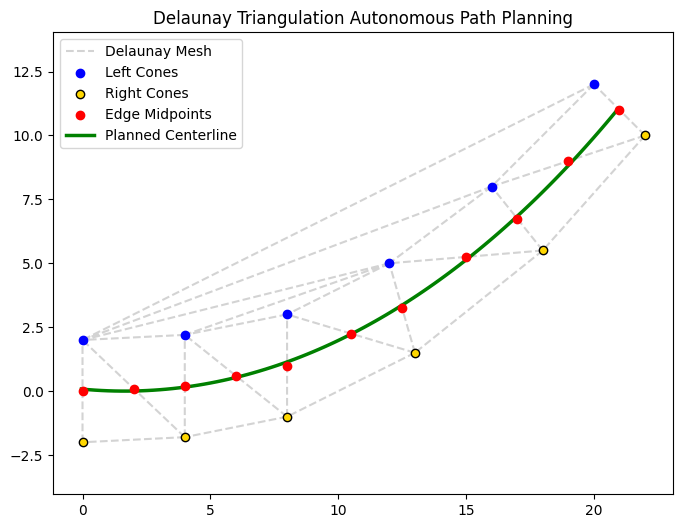

In [1]:
# This script demonstrates a simple autonomous path planning algorithm 
# using Delaunay triangulation and cubic B-spline smoothing. 
# It generates a set of sample track cones, computes the Delaunay triangulation, 
# extracts internal cross-track edges, calculates midpoints, 
# orders them to form a path, and finally smooths the path using a cubic B-spline. 
# The resulting path is visualized along with the original cones and triangulation mesh.
# It is generated by cloud-based AI from following link 
# https://blogs.mathworks.com/student-lounge/2022/10/03/path-planning-for-formula-student-driverless-cars-using-delaunay-triangulation/

import numpy as np
from scipy.spatial import Delaunay
from scipy.interpolate import splprep, splev
import matplotlib.pyplot as plt

# 1. Sample Track Cones (Left = Blue, Right = Yellow)
blue_cones = np.array([[0, 2], [4, 2.2], [8, 3], [12, 5], [16, 8], [20, 12]])
yellow_cones = np.array([[0, -2], [4, -1.8], [8, -1], [13, 1.5], [18, 5.5], [22, 10]])

# Combine points and track their boundary labels (0 = Left, 1 = Right)
points = np.vstack((blue_cones, yellow_cones))
labels = np.array([0] * len(blue_cones) + [1] * len(yellow_cones))

# 2. Compute 2D Delaunay Triangulation
tri = Delaunay(points)

# 3. Extract Internal Cross-Track Edges & Calculate Midpoints
midpoints = []
seen_edges = set()

for simplex in tri.simplices:
    edges = [(simplex[0], simplex[1]), (simplex[1], simplex[2]), (simplex[2], simplex[0])]
    for u, v in edges:
        edge = tuple(sorted((u, v)))
        if edge in seen_edges:
            continue
        seen_edges.add(edge)
        
        # Keep only edges connecting opposite track boundaries (Blue to Yellow)
        if labels[u] != labels[v]:
            dist = np.linalg.norm(points[u] - points[v])
            if dist < 8.0:
                midpoints.append((points[u] + points[v]) / 2.0)

midpoints = np.array(midpoints)

# 4. Order Midpoints Greedily & Deduplicate Consecutive Points
car_pos = np.array([0.0, 0.0])
ordered_path = [car_pos]
remaining = list(midpoints)

while remaining:
    current = ordered_path[-1]
    distances = [np.linalg.norm(p - current) for p in remaining]
    nearest_idx = int(np.argmin(distances))
    next_pt = remaining.pop(nearest_idx)
    
    # Prevent duplicate consecutive points that crash splprep
    if np.linalg.norm(next_pt - current) > 1e-6:
        ordered_path.append(next_pt)

ordered_path = np.array(ordered_path)

# 5. Smooth Path with Cubic B-Spline (Safely handle short point lists)
if len(ordered_path) > 1:
    k_deg = min(3, len(ordered_path) - 1)
    tck, u = splprep([ordered_path[:, 0], ordered_path[:, 1]], s=0.5, k=k_deg)
    u_fine = np.linspace(0, 1, 100)
    smooth_x, smooth_y = splev(u_fine, tck)
else:
    smooth_x, smooth_y = ordered_path[:, 0], ordered_path[:, 1]

# Visualization
plt.figure(figsize=(8, 6))
plt.triplot(points[:, 0], points[:, 1], tri.simplices, color='lightgray', linestyle='--', label='Delaunay Mesh')
plt.scatter(blue_cones[:, 0], blue_cones[:, 1], c='blue', label='Left Cones')
plt.scatter(yellow_cones[:, 0], yellow_cones[:, 1], c='gold', edgecolors='black', label='Right Cones')
plt.scatter(midpoints[:, 0], midpoints[:, 1], c='red', zorder=5, label='Edge Midpoints')
plt.plot(smooth_x, smooth_y, 'g-', linewidth=2.5, label='Planned Centerline')
plt.legend()
plt.axis('equal')
plt.title('Delaunay Triangulation Autonomous Path Planning')
plt.show()
